# Irrigation Study (Colab): Forecasting + Groundwater Dependence + District Typology
Upload together: `irrigation_pipeline.py`, `study_pipeline.py` and the 4 CSVs (or use the Drive cell).
Optional: Runtime → T4 GPU (only needed for the GRU section).

In [1]:
from google.colab import files
import os
os.makedirs('/content/study', exist_ok=True)
%cd /content/study
uploaded = files.upload()

/content/study


In [2]:
# Alternative: Google Drive (put the 6 files in MyDrive/irrigation_project/)
# from google.colab import drive; drive.mount('/content/drive')
# %cd /content/drive/MyDrive/irrigation_project

In [1]:
from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/MyDrive/irrigation_project
!ls

Mounted at /content/drive
/content/drive/MyDrive/irrigation_project
Area_Under_Crops_codebook.xlsx		name_crosswalk_REVIEW_boundaries.csv
area-under-crops.csv			__pycache__
Classification_of_Area_codebook.xlsx	Sources_of_Irrigation_codebook.xlsx
classification-of-area.csv		sources-of-irrigation.csv
Crop_Wise_Irrigated_Area_codebook.xlsx	study_extensions.py
crop-wise-irrigated-area.csv		study_outputs
districts_census2011.geojson		study_pipeline.py
irrigation_pipeline.py			study_results.zip
irrigation_study_colab.ipynb


In [6]:
import pandas as pd, os, importlib
import irrigation_pipeline as ip, study_pipeline as sp
from IPython.display import Image, display
OUT = 'study_outputs'; os.makedirs(OUT, exist_ok=True)

## A. Build + clean panel

In [7]:
panel = ip.build_panel('.')
df = sp.clean_panel(panel)
print(df.shape)

[Clean] rows flagged as implausible: 118 (0.8%)
(15082, 122)


## B. Groundwater & irrigation trends per district (Kendall test + Theil-Sen slope)

In [8]:
tr = sp.trend_analysis(df, OUT)
display(pd.read_csv(f'{OUT}/state_groundwater_trends.csv').head(15))

[Trend] groundwater-share trend classes:
 gw_trend_class
insufficient data       255
rising                  231
no significant trend    172
declining                83
[Trend] irrigation-intensity trend classes:
 irr_trend_class
rising                  365
insufficient data       181
no significant trend    150
declining                45


,state_name,districts,pct_gw_rising,median_gw_slope_per_decade
0,Kerala,14,85.714286,0.064437
1,Andhra Pradesh,13,76.923077,0.044798
2,Karnataka,29,72.413793,0.100116
3,Chhattisgarh,18,72.222222,0.087522
4,Haryana,21,71.428571,0.058921
5,Uttarakhand,7,71.428571,0.044428
6,Tamil Nadu,31,70.967742,0.060484
7,Uttar Pradesh,69,63.768116,0.026993
8,Punjab,20,55.000000,0.010566
9,Assam,25,52.000000,0.055181


## C. District typology (clusters on recent profile + long-run trends)

[Typology] silhouette: {3: np.float64(0.089), 4: np.float64(0.1), 5: np.float64(0.101), 6: np.float64(0.101), 7: np.float64(0.108), 8: np.float64(0.117)} -> k = 8
         irrigation_intensity  groundwater_share  canal_share  fallow_share  n_districts                               top_states
cluster                                                                                                                          
0                       0.739              0.693        0.159         0.042           75       Madhya Pradesh, Rajasthan, Gujarat
1                       0.274              0.277        0.373         0.066          114                 Assam, Kerala, Karnataka
2                       1.000              0.721        0.279         0.013           18                                   Punjab
3                       0.362              0.693        0.298         0.138           10                                Rajasthan
4                       0.751              0.743        0

,cluster,irrigation_intensity,cropping_intensity,groundwater_share,canal_share,tank_share,fallow_share,forest_share,sown_share,crop_entropy,groundwater_share_slope,irrigation_intensity_slope,n_districts,top_states
0,0,0.739,1.729,0.693,0.159,0.031,0.042,0.201,0.527,1.169,0.003,0.200,75,"Madhya Pradesh, Rajasthan, Gujarat"
1,1,0.274,1.343,0.277,0.373,0.057,0.066,0.352,0.319,1.452,0.059,0.032,114,"Assam, Kerala, Karnataka"
2,2,1.000,1.886,0.721,0.279,0.000,0.013,0.053,0.821,0.579,0.029,0.022,18,Punjab
3,3,0.362,1.354,0.693,0.298,0.008,0.138,0.030,0.556,1.529,0.054,0.063,10,Rajasthan
4,4,0.751,1.683,0.743,0.206,0.014,0.070,0.050,0.655,0.947,0.028,0.043,181,"Uttar Pradesh, Bihar, Haryana"
5,5,0.329,1.344,0.647,0.270,0.042,0.106,0.145,0.546,1.464,0.018,0.059,118,"Maharashtra, Gujarat, Telangana"
6,6,0.382,1.297,0.379,0.080,0.361,0.277,0.239,0.223,0.881,-0.040,0.044,41,"Jharkhand, Tamil Nadu, Andhra Pradesh"
7,7,0.291,1.351,0.169,0.293,0.012,0.094,0.250,0.362,0.721,0.028,0.017,170,"Odisha, Chhattisgarh, Arunachal Pradesh"


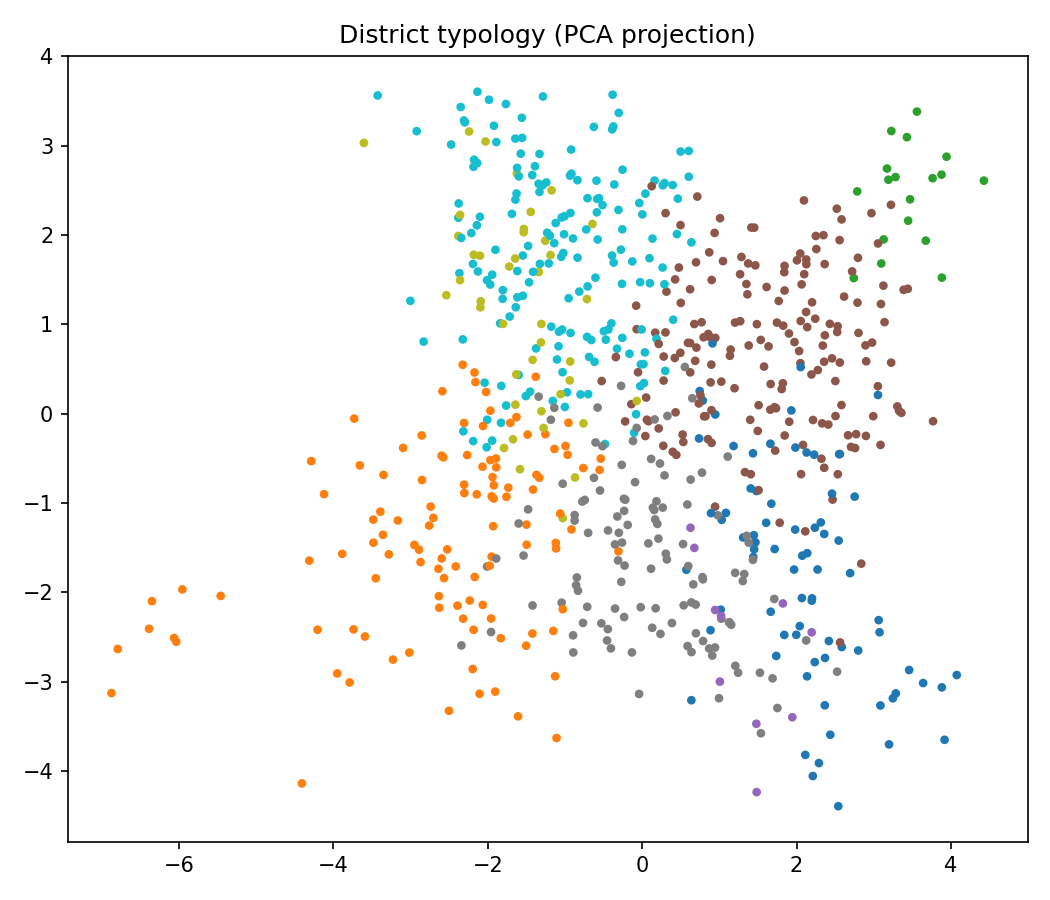

In [9]:
clusters = sp.typology(df, tr, OUT)
display(pd.read_csv(f'{OUT}/cluster_summary.csv'))
Image(f'{OUT}/typology_pca.png')

## D. Multi-horizon forecasting (1, 3, 5 years) vs persistence baseline

In [10]:
results, preds = sp.multi_horizon_forecast(df, OUT)
results.pivot_table(index=['target','horizon'], columns='model', values='MAE').round(4)

[Forecast]
               target  horizon       model    MAE     R2  skill_vs_persistence  n_test
irrigation_intensity        1 persistence 0.0511 0.8898                0.0000    1582
irrigation_intensity        1       ridge 0.0535 0.9021               -0.0472    1582
irrigation_intensity        1    hist_gbm 0.0525 0.9073               -0.0268    1582
irrigation_intensity        3 persistence 0.0645 0.8754                0.0000    1542
irrigation_intensity        3       ridge 0.0688 0.8777               -0.0664    1542
irrigation_intensity        3    hist_gbm 0.0706 0.8743               -0.0949    1542
irrigation_intensity        5 persistence 0.0856 0.8176                0.0000    1503
irrigation_intensity        5       ridge 0.0864 0.8310               -0.0085    1503
irrigation_intensity        5    hist_gbm 0.0856 0.8348                0.0006    1503
   groundwater_share        1 persistence 0.0492 0.8939                0.0000    1475
   groundwater_share        1       ridge 

model                         hist_gbm  persistence   ridge
target               horizon                               
groundwater_share    1          0.0533       0.0492  0.0548
                     3          0.0836       0.0679  0.0760
                     5          0.0930       0.0809  0.0903
irrigation_intensity 1          0.0525       0.0511  0.0535
                     3          0.0706       0.0645  0.0688
                     5          0.0856       0.0856  0.0864

## E. Integration: where is forecasting hard, and how do clusters relate to groundwater trends?

[Integrate] 3-yr forecast error by cluster:
          abs_err_persist  abs_err_gbm   skill
cluster                                      
0                 0.0984       0.0965  0.0194
1                 0.0355       0.0401 -0.1298
2                 0.0000       0.0078    -inf
3                 0.0249       0.0351 -0.4093
4                 0.0647       0.0731 -0.1301
5                 0.0921       0.0945 -0.0270
6                 0.0764       0.0834 -0.0905
7                 0.0590       0.0682 -0.1557
[Integrate] % of districts per groundwater-trend class, by cluster:
 col_0    declining  insufficient data  no significant trend  rising
cluster                                                            
0             25.3                1.3                  33.3    40.0
1              3.5               54.4                   9.6    32.5
2             16.7               11.1                  22.2    50.0
3             10.0               40.0                  20.0    30.0
4              9.4

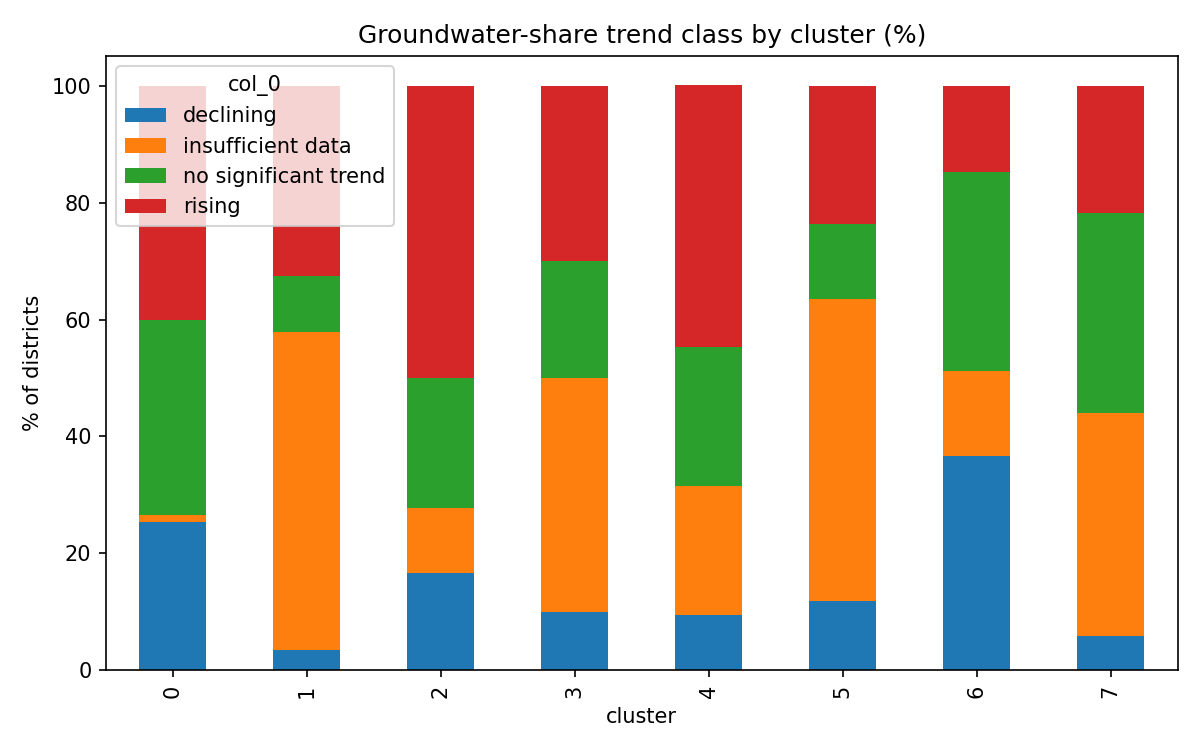

In [11]:
sp.integrate(preds, clusters, tr, OUT)
Image(f'{OUT}/cluster_vs_groundwater_trend.png')

## F. (Optional) Deep learning GRU benchmark

In [13]:
ip.task_dl_forecast(df, OUT, window=5, epochs=60)

[DL] sequences train/val/test = 8035/1703/1635
[DL] GRU test MAE=0.0581  R2=0.893


In [10]:
!python study_extensions.py

No cached panel found -> rebuilding from raw CSVs (takes a few minutes)
[Clean] rows flagged as implausible: 118 (0.8%)
[Robust trends]
            indicator   method  rising  declining  tested
   groundwater_share      raw     231         83     486
   groundwater_share     tfpw     240         88     486
   groundwater_share tfpw+fdr     233         86     486
irrigation_intensity      raw     365         45     560
irrigation_intensity     tfpw     377         56     560
irrigation_intensity tfpw+fdr     367         56     560
[Cluster stability]
  k  silhouette  boot_ARI_mean  boot_ARI_sd   gmm_BIC  kmeans_vs_gmm_ARI
 3       0.089          0.546        0.210 27051.998              0.232
 4       0.100          0.661        0.178 22396.353              0.310
 5       0.101          0.623        0.102 17510.750              0.294
 6       0.101          0.457        0.098 16904.097              0.338
 7       0.108          0.552        0.103 12910.390              0.247
 8       0.

## G. Download everything

In [4]:
!pip -q install imdlib geopandas shapely xarray


In [9]:
!ls

Area_Under_Crops_codebook.xlsx		irrigation_study_colab.ipynb
area-under-crops.csv			name_crosswalk_REVIEW_boundaries.csv
Classification_of_Area_codebook.xlsx	__pycache__
classification-of-area.csv		Sources_of_Irrigation_codebook.xlsx
Crop_Wise_Irrigated_Area_codebook.xlsx	sources-of-irrigation.csv
crop-wise-irrigated-area.csv		study_extensions.py
districts_census2011.geojson		study_outputs
external_covariates.py			study_pipeline.py
irrigation_pipeline.py			study_results.zip


In [11]:
import sys, os
sys.path.insert(0, os.getcwd())




In [13]:
%cd /content/drive/MyDrive/irrigation_project
!ls -l external_covariates.py

/content/drive/MyDrive/irrigation_project
-rw------- 1 root root 14406 Nov 15 15:41 external_covariates.py


In [31]:
import os, sys, importlib, importlib.util

folder = "/content/drive/MyDrive/irrigation_project"
os.chdir(folder)
if folder not in sys.path:
    sys.path.insert(0, folder)

importlib.invalidate_caches()          # forget the old directory listing
sys.modules.pop("external_covariates", None)

try:
    import external_covariates as ec
except ModuleNotFoundError:
    # load straight from the file path, bypassing the search path
    spec = importlib.util.spec_from_file_location("external_covariates", f"{folder}/external_covariates.py")
    ec = importlib.util.module_from_spec(spec)
    sys.modules["external_covariates"] = ec
    spec.loader.exec_module(ec)

print("IMPORT OK:", ec.__file__)
print([n for n in dir(ec) if not n.startswith("_")][:12])

IMPORT OK: /content/drive/MyDrive/irrigation_project/external_covariates.py
['KEYS', 'SEED', 'build_crosswalk', 'difflib', 'forecast_with_covariates', 'groundwater_district_year', 'groundwater_validation', 'inspect_file', 'load_districts', 'merge_covariates', 'norm_name', 'np']


In [32]:
!pip -q install imdlib geopandas shapely xarray
print("gdf projection:", gdf.crs)
print(gdf.info())

gdf projection: EPSG:4326
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 641 entries, 0 to 640
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   state_name     641 non-null    object  
 1   district_name  641 non-null    object  
 2   geometry       641 non-null    geometry
dtypes: geometry(1), object(2)
memory usage: 15.2+ KB
None


In [33]:
gdf = ec.load_districts("districts_census2011.geojson", state_col="ST_NM", district_col="DISTRICT")
print(gdf.shape)      # expect (641, 3)
gdf.head()

(641, 3)


,state_name,district_name,geometry
0,Andhra Pradesh,Adilabad,"POLYGON ((78.84972 19.7601, 78.8689 19.69797, ..."
1,Uttar Pradesh,Agra,"POLYGON ((78.17946 27.40883, 78.22602 27.40584..."
2,Gujarat,Ahmadabad,"MULTIPOLYGON (((72.03456 23.50527, 72.02583 23..."
3,Maharashtra,Ahmadnagar,"POLYGON ((74.67333 19.9467, 74.68195 19.92493,..."
4,Mizoram,Aizawl,"POLYGON ((92.97944 24.40659, 93.02345 24.38727..."


In [21]:
!pip -q install imdlib

In [34]:
rain_test = ec.rainfall_for_districts(gdf, 2000, 2000, file_dir="imd_test")
print(rain_test.shape)                       # expect about (641, 7)
print(rain_test[["rain_monsoon","rain_agyear","rain_wetdays"]].describe().round(0))

File already exists: imd_test/rain/2000.grd. Skipping download.
File already exists: imd_test/rain/2001.grd. Skipping download.
Download Successful !!!
(641, 7)
       rain_monsoon  rain_agyear  rain_wetdays
count         641.0        641.0         641.0
mean          881.0       1121.0          49.0
std           573.0        727.0          22.0
min             0.0          0.0           0.0
25%           479.0        648.0          32.0
50%           798.0        949.0          48.0
75%          1109.0       1380.0          64.0
max          3850.0       5033.0         108.0


In [23]:
rain = ec.rainfall_for_districts(gdf, 1998, 2023, file_dir="imd_data")
print(rain.shape)                            # expect about (16,000+, 7)

Downloading: rain for year 1998
Downloading: rain for year 1999
Downloading: rain for year 2000
Downloading: rain for year 2001
Downloading: rain for year 2002
Downloading: rain for year 2003
Downloading: rain for year 2004
Downloading: rain for year 2005
Downloading: rain for year 2006
Downloading: rain for year 2007
Downloading: rain for year 2008
Downloading: rain for year 2009
Downloading: rain for year 2010
Downloading: rain for year 2011
Downloading: rain for year 2012
Downloading: rain for year 2013
Downloading: rain for year 2014
Downloading: rain for year 2015
Downloading: rain for year 2016
Downloading: rain for year 2017
Downloading: rain for year 2018
Downloading: rain for year 2019
Downloading: rain for year 2020
Downloading: rain for year 2021
Downloading: rain for year 2022
Downloading: rain for year 2023
Downloading: rain for year 2024
Download Successful !!!
rain 1998 done
rain 1999 done
rain 2000 done
rain 2001 done
rain 2002 done
rain 2003 done
rain 2004 done
rain 20

In [35]:
import os, glob
os.chdir("/content/drive/MyDrive/irrigation_project")

known = {"area-under-crops.csv", "classification-of-area.csv", "crop-wise-irrigated-area.csv",
         "sources-of-irrigation.csv", "name_crosswalk_REVIEW_boundaries.csv"}
candidates = [f for f in glob.glob("*.csv") if f not in known]

print("Rainfall done:", os.path.exists("imd_data/district_rainfall.csv") or os.path.exists("imd_test/district_rainfall.csv"))
print("Possible groundwater files:", candidates if candidates else "NONE FOUND")

if candidates:
    gw_file = candidates[0]
    print("\nInspecting:", gw_file)
    ec.inspect_file(gw_file)

Rainfall done: True
Possible groundwater files: ['cgwb-changes-in-depth-to-water-level.csv', 'groundwater_validation_districts.csv', 'gw_district_year.csv']

Inspecting: cgwb-changes-in-depth-to-water-level.csv
id                 int64
date              object
state_name        object
state_code         int64
district_name     object
district_code      int64
station_name      object
latitude         float64
longitude        float64
basin             object
sub_basin         object
source            object
currentlevel     float64
level_diff       float64
   id        date                   state_name  state_code             district_name  district_code station_name  latitude  longitude                                               basin                                     sub_basin source  currentlevel  level_diff
0   0  2013-11-04  Andaman And Nicobar Islands          35  North And Middle Andaman            632     Laxmipur  13.28556   93.00306  Drainage Area Of Andaman And Nicobar Is

In [39]:
import os, pandas as pd, importlib
os.chdir("/content/drive/MyDrive/irrigation_project")
importlib.invalidate_caches(); importlib.reload(ec)

for p in ["imd_data/district_rainfall.csv", "imd_test/district_rainfall.csv"]:
    if os.path.exists(p):
        r = pd.read_csv(p)
        print(p, r.shape, "| years", int(r.year_start.min()), "-", int(r.year_start.max()))
        print(r[["rain_monsoon","rain_agyear","rain_wetdays"]].describe().round(0).T)

imd_data/district_rainfall.csv (16666, 7) | years 1998 - 2023
                count    mean    std  min    25%     50%     75%      max
rain_monsoon  16666.0   932.0  642.0  0.0  519.0   821.0  1159.0   8931.0
rain_agyear   16666.0  1250.0  814.0  0.0  734.0  1067.0  1521.0  10486.0
rain_wetdays  16666.0    49.0   21.0  0.0   33.0    48.0    64.0    115.0
imd_test/district_rainfall.csv (641, 7) | years 2000 - 2000
              count    mean    std  min    25%    50%     75%     max
rain_monsoon  641.0   881.0  573.0  0.0  479.0  798.0  1109.0  3850.0
rain_agyear   641.0  1121.0  727.0  0.0  648.0  949.0  1380.0  5033.0
rain_wetdays  641.0    49.0   22.0  0.0   32.0   48.0    64.0   108.0


In [41]:
import numpy as np

def fill_missing_with_state_mean(full, cols=("rain_monsoon", "rain_agyear", "rain_postmonsoon", "rain_wetdays")):
    out = full.copy()
    cols = [c for c in cols if c in out.columns]
    first = cols[0]
    out["rain_state_filled"] = out[first].isna().astype(int)
    for c in cols:
        m = out.groupby(["state_code", "year_start"])[c].transform("mean")
        out[c] = out[c].fillna(m)
    still = out[first].isna() & out.year_start.between(1998, 2023)
    print(f"[Rain fill] filled {int(out.rain_state_filled.sum())} district-years with state means; "
          f"{int(still.sum())} still missing")
    return out

full = fill_missing_with_state_mean(full)
print(full[["rain_monsoon", "gw_post"]].notna().mean().round(2))
full.to_csv("study_outputs/panel_with_covariates.csv", index=False)

[Rain fill] filled 2479 district-years with state means; 541 still missing
rain_monsoon    0.96
gw_post         0.22
dtype: float64


In [42]:
res = ec.forecast_with_covariates(full, "study_outputs")

[Forecast + covariates]
               target  horizon               model    MAE  skill_vs_persistence  skill_CI_low  skill_CI_high  n_test
irrigation_intensity        1         persistence 0.0511                0.0000           NaN            NaN    1582
irrigation_intensity        1   state_mean_change 0.0520               -0.0167       -0.0236        -0.0104    1582
irrigation_intensity        1            gbm_base 0.0545               -0.0669       -0.1167        -0.0251    1582
irrigation_intensity        1 gbm_plus_covariates 0.0520               -0.0172       -0.0498         0.0113    1582
irrigation_intensity        1     gbm_oracle_rain 0.0523               -0.0228       -0.0595         0.0085    1582
irrigation_intensity        3         persistence 0.0645                0.0000           NaN            NaN    1542
irrigation_intensity        3   state_mean_change 0.0654               -0.0138       -0.0343         0.0040    1542
irrigation_intensity        3            gbm_ba